In [2]:
import numpy as np
# import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.io import loadmat

In [3]:
def load_biomass_data(
    parent_path,
    band_opt,
    heading,
    acquisition_mode,
    polarimetric_channel,
    
):
    # Loading data
    # Loading angles
    angles_path = f"{parent_path}{band_opt}/PowerCubeGeocod/AnglesUTM.mat"
    angles_data = loadmat(angles_path)
    IncAngleUTM = angles_data['IncAngleUTM']
    easting_axis = angles_data['easting_axis'].squeeze()
    northing_axis = angles_data['northing_axis'].squeeze()

    # Loading LiDAR data
    lidar_path = f"{parent_path}{band_opt}/PowerCubeGeocod/LidarUTM.mat"
    lidar_data = loadmat(lidar_path)
    LidarCHM = lidar_data['LidarCHM']

    # Loading normalized SAR intensity data cube (coherence?)
    pcube_norm_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeNormUTM.mat"
    pcube_norm_data = loadmat(pcube_norm_path)
    PcubeNormUTM = pcube_norm_data['PcubeNormUTM']
    z_axis = pcube_norm_data['z_axis'].squeeze()

    # Loading SAR intensity data cube
    if band_opt == 'P':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedUTM = sar_intensity_data['PcubeDeRampedUTM']
    elif band_opt == 'L':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedDeBiasedUTM = sar_intensity_data['PcubeDeRampedDeBiasedUTM']

    # Determine the indices based on string options
    head_ind = 1 if heading == 'NW' else 2
    mono_bi_ind = 1 if acquisition_mode == 'monostatic' else 2
    pol_ind = {'HH': 1, 'HV': 2, 'VV': 3}[polarimetric_channel]

    return {
        'IncAngleUTM': IncAngleUTM,
        'easting_axis': easting_axis,
        'northing_axis': northing_axis,
        'LidarCHM': LidarCHM,
        'PcubeNormUTM': PcubeNormUTM,
        'z_axis': z_axis,
        'PcubeUTM': PcubeDeRampedUTM if band_opt == 'P' else PcubeDeRampedDeBiasedUTM,
        'head_ind': head_ind,
        'mono_bi_ind': mono_bi_ind,
        'pol_ind': pol_ind
    }

In [4]:

# Example usage
parent_path = '/home/takataka_ju/data/tomosar-matlab/'
band_opt = 'L'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HV'
# above_ground_elevation = 20

data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

# Access the returned objects
IncAngleUTM = data['IncAngleUTM']
easting_axis = data['easting_axis']
northing_axis = data['northing_axis']
LidarCHM = data['LidarCHM']
PcubeNormUTM = data['PcubeNormUTM']
z_axis = data['z_axis']
PcubeUTM = data['PcubeUTM']
head_ind = data['head_ind']
mono_bi_ind = data['mono_bi_ind']
pol_ind = data['pol_ind']


In [5]:
import numpy as np
import pandas as pd

def lidar_cube_to_table(lidar_cube):
    """
    Converts a LiDAR cube into a table with columns x, y, and lidar.

    Parameters:
    - lidar_cube: np.array of shape (x_dim, y_dim) where dimensions are (x, y, lidar)

    Returns:
    - pd.DataFrame with columns [x, y, lidar]
    """
    x_dim, y_dim = lidar_cube.shape
    records = []

    for x in range(x_dim):
        for y in range(y_dim):
            lidar_value = lidar_cube[x, y]
            records.append([x, y, lidar_value])

    # Create DataFrame
    df = pd.DataFrame(records, columns=['x', 'y', 'lidar'])
    return df

# Example usage

lidar_df = lidar_cube_to_table(LidarCHM)
print(lidar_df)


          x    y  lidar
0         0    0    NaN
1         0    1    NaN
2         0    2    NaN
3         0    3    NaN
4         0    4    NaN
...     ...  ...    ...
273835  325  835    NaN
273836  325  836    NaN
273837  325  837    NaN
273838  325  838    NaN
273839  325  839    NaN

[273840 rows x 3 columns]


In [6]:
lidar_df.lidar.isna().sum()

np.int64(60375)

In [7]:
lidar_df.shape

(273840, 3)

In [8]:
# p cube de ramped 
PcubeUTM.shape
#  x , y , z, polarimetry, heading, acquisition_mode 


(326, 840, 36, 3, 2, 2)

In [9]:
PcubeUTM[0:10, 0:10, :, :, :, :].shape

10 * 10  * 3 * 2 

600

In [10]:
print(PcubeUTM.shape)


(326, 840, 36, 3, 2, 2)


In [11]:
import numpy as np
import pandas as pd

def extract_z_vectors(data):
    """
    Extracts z vectors for each (x, y) point in the given data and stores them in a table with additional information.

    Parameters:
    - data: np.array of shape (326, 840, 36, 3, 2) where dimensions are (x, y, z, polarimetry, heading, acquisition_mode)

    Returns:
    - pd.DataFrame with columns [x, y, z_0, z_1, ..., z_n, polarimetry, heading, polarimetry] where z_n is the max value of z.
    """
    x_dim, y_dim, z_dim, pol_dim, head_dim, acq_dim = data.shape
    records = []

    for heading in range(head_dim):
        for polarimetry in range(pol_dim):
            for acquisition_mode in range(acq_dim):
                for x in range(x_dim):
                    for y in range(y_dim):
                        z_vector = data[x, y, :, polarimetry, heading, acquisition_mode]
                        record = [x, y] + z_vector.tolist() + [heading, polarimetry, acquisition_mode]
                        records.append(record)

    # Generate column names: x, y, z_0, z_1, ..., z_n, heading, polarimetry
    columns = ['x', 'y'] + [f'z_{i}' for i in range(z_dim)] + ['heading', 'polarimetry', 'acquisition_mode']
    
    df = pd.DataFrame(records, columns=columns)
    return df

# Example usage

df = extract_z_vectors(PcubeUTM[0:10, 0:10, :, :, :, :])
print(df)


      x  y  z_0  z_1  z_2  z_3  z_4  z_5  z_6  z_7  ...  z_29  z_30  z_31  \
0     0  0  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
1     0  1  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
2     0  2  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
3     0  3  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
4     0  4  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
...  .. ..  ...  ...  ...  ...  ...  ...  ...  ...  ...   ...   ...   ...   
1195  9  5  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
1196  9  6  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
1197  9  7  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
1198  9  8  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   
1199  9  9  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   NaN   

      z_32  z_33  z_34  z_35  heading  polarimetry  acquisition_mode  
0   

In [12]:
df = extract_z_vectors(PcubeUTM)
print(df)

           x    y  z_0  z_1  z_2  z_3  z_4  z_5  z_6  z_7  ...  z_29  z_30  \
0          0    0  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
1          0    1  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
2          0    2  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
3          0    3  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
4          0    4  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
...      ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   ...   ...   
3286075  325  835  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
3286076  325  836  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
3286077  325  837  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
3286078  325  838  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   
3286079  325  839  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   NaN   NaN   

         z_31  z_32  z_33  z_34  z_35  heading  polarimetry  ac

In [13]:
len(df)

3286080

In [14]:

# Identify the columns corresponding to the z values
z_columns = [col for col in df.columns if col.startswith('z_')]

# Filter out rows where all z values are 0
df_filtered = df.loc[~(df[z_columns].isna()).all(axis=1)]

print(df_filtered.shape)


(1186806, 41)


In [15]:
mldata = df_filtered.merge(lidar_df, on=['x', 'y'])
cl_ml_data = mldata[~mldata['lidar'].isna()]

In [16]:
cl_ml_data.shape

(1170690, 42)

/usr/local/lib/python3.10/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


<Axes: >

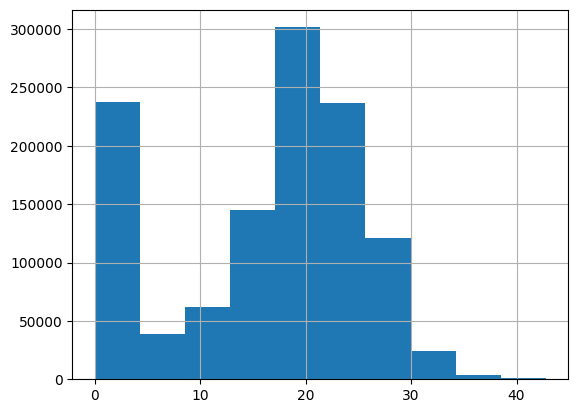

In [17]:
cl_ml_data.lidar.hist()

In [18]:
cl_ml_data.to_csv('ml_ready_data_lidar_pcube_lband.csv', index=False )

In [ ]:
# ddata array PcubeDeRampedUTM , of  shape (326, 840, 36, 3, 2), where dims are  x , y , z, polarimetry, heading 
#  loop over heading 1, 0 
#  loop over polarimaety 0,1,2 
# for cube of x y,  z, for each point x,y extract the z vector at that point 
# store in table waith vols, x,y, z_0, z_1...Z-n, heading, polarimetry  where z_n is the max value of z. 

In [ ]:
# in the overlapping areas take the max value 
#  heading Nw and SE 
# overlapping areas 
# chop out ther areas with missing area 